# 01 Explore the 2015/16 Premier League

Week 1 goal is to get comfortable with StatsBomb events. Run `python -m pipeline.ingest_statsbomb --league "Premier League"` first.

In [1]:
import sys

sys.path.append('..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mplsoccer import Pitch, VerticalPitch

from pipeline.ingest_statsbomb import load_events

events = load_events(['Premier League'])
print(f'{len(events):,} events, {events.match_id.nunique()} matches')
events.type.value_counts().head(10)

1,313,773 events, 380 matches


type
Pass             368619
Ball Receipt*    340314
Carry            276949
Pressure         115402
Ball Recovery     40943
Duel              32290
Clearance         21645
Block             14839
Dribble           13721
Goal Keeper       11777
Name: count, dtype: int64

## 1. What does one shot look like?

In [2]:
shots = events[events.type == 'Shot'].copy()
shots['xg'] = shots.shot_statsbomb_xg.astype(float)
shots['goal'] = shots.shot_outcome == 'Goal'
cols = ['minute', 'team', 'player', 'location', 'shot_type', 'shot_body_part', 'shot_outcome', 'xg']
shots[cols].head()

,minute,team,player,location,shot_type,shot_body_part,shot_outcome,xg
3575,7,Arsenal,Ignacio Monreal Eraso,"[107.6, 28.2]",Open Play,Left Foot,Off T,0.058629
3576,15,Arsenal,Joel Nathaniel Campbell Samuels,"[99.8, 52.8]",Open Play,Left Foot,Off T,0.040084
3577,26,Swansea City,Bafétimbi Gomis,"[110.4, 45.9]",Open Play,Head,Saved,0.117854
3578,28,Arsenal,Olivier Giroud,"[104.5, 46.9]",Open Play,Left Foot,Off T,0.203382
3579,31,Swansea City,Gylfi Þór Sigurðsson,"[100.1, 21.1]",Free Kick,Right Foot,Blocked,0.012535


## 2. Every shot of the season, sized by StatsBomb xG

Goals in colour, misses in grey. Notice how goals cluster inside the box and in the centre.

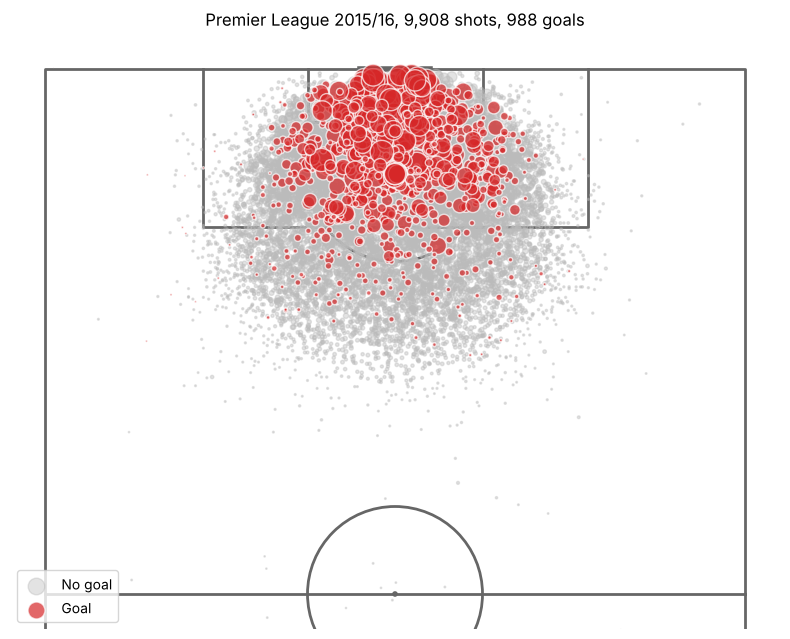

In [3]:
pitch = VerticalPitch(pitch_type='statsbomb', half=True, line_color='#666', pitch_color='white')
fig, ax = pitch.draw(figsize=(8, 7))
xy = np.vstack(shots.location.to_numpy())
miss, goal = ~shots.goal.to_numpy(), shots.goal.to_numpy()
pitch.scatter(xy[miss, 0], xy[miss, 1], s=shots.xg[miss] * 300, color='#bbb', alpha=0.4, ax=ax, label='No goal')
pitch.scatter(xy[goal, 0], xy[goal, 1], s=shots.xg[goal] * 300, color='#d62728', alpha=0.7, edgecolors='white', ax=ax, label='Goal')
ax.legend(loc='lower left')
ax.set_title(f'Premier League 2015/16, {len(shots):,} shots, {goal.sum()} goals')
plt.show()

## 3. Leicester's title season, top xG players

In [4]:
lei = shots[(shots.team == 'Leicester City') & (shots.shot_type != 'Penalty')]
lei.groupby('player').agg(shots=('xg', 'size'), npxg=('xg', 'sum'), goals=('goal', 'sum')).sort_values('npxg', ascending=False).head(8).round(2)

,shots,npxg,goals
player,,,
Jamie Vardy,112,17.60,19
Riyad Mahrez,81,7.46,13
Shinji Okazaki,44,7.12,5
José Leonardo Ulloa,32,5.64,5
Wes Morgan,21,2.95,2
Robert Huth,30,2.60,3
Marc Albrighton,42,2.36,2
Jeffrey Schlupp,25,2.14,1


## 4. Pass map for one player in one match

Completed passes in blue, incomplete in red.

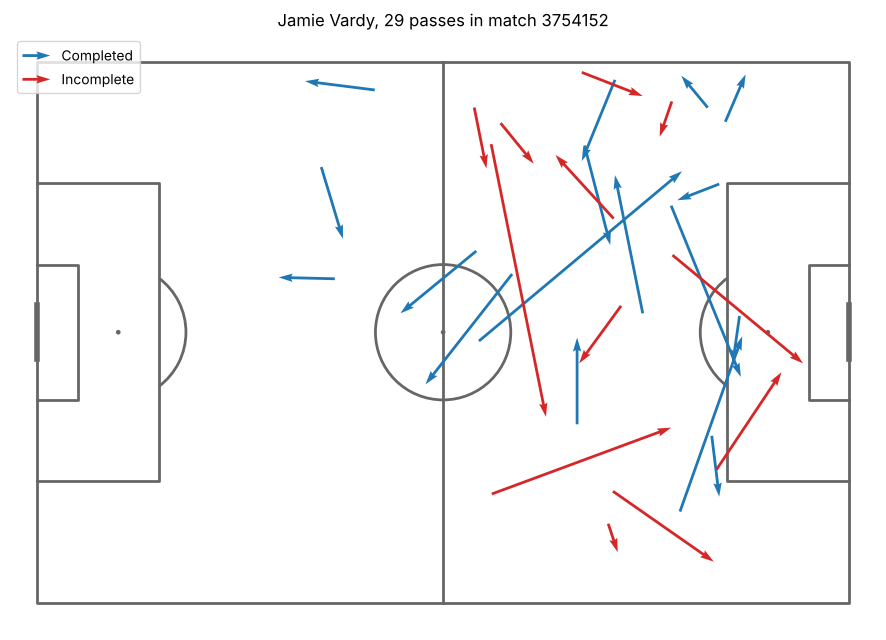

In [5]:
player = lei.groupby('player').xg.sum().idxmax()
passes = events[(events.type == 'Pass') & (events.player == player)]
match_id = passes.match_id.value_counts().idxmax()
p = passes[passes.match_id == match_id]
ok = p.pass_outcome.isna().to_numpy()
s = np.vstack(p.location.to_numpy())
e = np.vstack(p.pass_end_location.to_numpy())
pitch = Pitch(pitch_type='statsbomb', line_color='#666')
fig, ax = pitch.draw(figsize=(10, 6.5))
pitch.arrows(s[ok, 0], s[ok, 1], e[ok, 0], e[ok, 1], width=2, color='#1f77b4', ax=ax, label='Completed')
pitch.arrows(s[~ok, 0], s[~ok, 1], e[~ok, 0], e[~ok, 1], width=2, color='#d62728', ax=ax, label='Incomplete')
ax.legend(loc='upper left')
ax.set_title(f'{player}, {len(p)} passes in match {match_id}')
plt.show()

## 5. Our first xG model vs StatsBomb

Same code as `python -m pipeline.xg_model`. Lower log loss is better.

In [6]:
from pipeline.xg_model import evaluate, shot_features

# Week 1 notebook. Since week 2, evaluate() compares several models
table, fitted = evaluate(events)
table.round(4)

,log_loss,brier,auc
model,,,
distance only,0.2927,0.0830,0.7158
week 1 logistic,0.2827,0.0799,0.7414
week 2 logistic + freeze frame,0.2762,0.0786,0.7650
week 2 gradient boosting + freeze frame,0.2834,0.0795,0.7515
StatsBomb xG (professional),0.2651,0.0745,0.7884


## 6. Is our model calibrated?

If the model says 0.2, about 20% of those shots should be goals. Points near the dashed line are good.

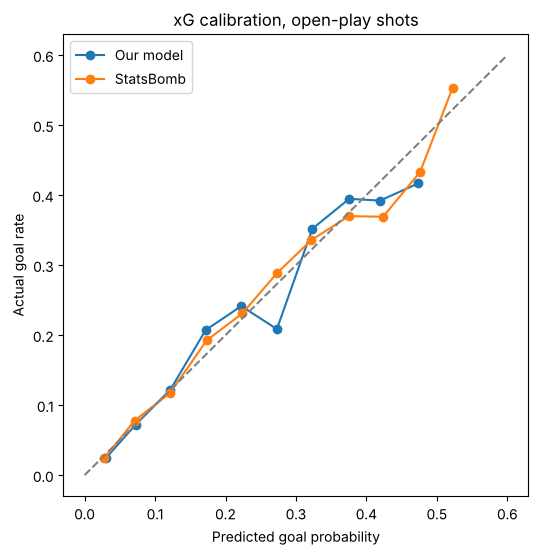

In [7]:
op = shots[shots.shot_type == 'Open Play']
model, cols = fitted['week 1 logistic']
op = op.assign(ours=model.predict_proba(shot_features(op)[cols])[:, 1])
bins = np.linspace(0, 0.6, 13)
fig, ax = plt.subplots(figsize=(6, 6))
for col, label in [('ours', 'Our model'), ('xg', 'StatsBomb')]:
    g = op.groupby(pd.cut(op[col], bins), observed=True).agg(pred=(col, 'mean'), actual=('goal', 'mean'), n=('goal', 'size'))
    g = g[g.n >= 30]
    ax.plot(g.pred, g.actual, marker='o', label=label)
ax.plot([0, 0.6], [0, 0.6], ls='--', color='grey')
ax.set_xlabel('Predicted goal probability')
ax.set_ylabel('Actual goal rate')
ax.legend()
ax.set_title('xG calibration, open-play shots')
plt.show()

## Notes for week 2

- Our model beats distance-only but trails StatsBomb. Freeze-frame features (defenders in the way, keeper position) should close the gap.
- Write what you noticed here before moving on.